In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,

    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Updated_Cleaned_RIT_Dataset.xlsx to Updated_Cleaned_RIT_Dataset (1).xlsx


In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [ ]:
file_path = "Updated_Cleaned_RIT_Dataset.xlsx"

df = pd.read_excel(file_path)

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [ ]:
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(8262, 19)


In [ ]:
df.head()

,Learner SignUp DateTime,Opportunity Id,Opportunity Name,Opportunity Category,Opportunity End Date,First Name,Date of Birth,Gender,Country,Institution Name,Current/Intended Major,Entry created at,Status Description,Status Code,Apply Date,Opportunity Start Date,Age_at_Signup,Signup_Month,Signup_Month_Name
0,2023-06-14 12:30:35,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Faria,2001-01-12,Female,Pakistan,Nwihs,Radiology,2024-03-11 12:01:41,Started,1080,2023-06-14 12:36:09,2022-11-03 18:30:39,22,6,June
1,2023-05-01 05:29:16,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Poojitha,2000-08-16,Female,India,Saint Louis University,Information Systems,2024-03-11 12:01:41,Started,1080,2023-05-01 06:08:21,2022-11-03 18:30:39,22,5,May
2,2023-04-09 20:35:08,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Emmanuel,2002-01-27,Male,United States,Illinois Institute Of Technology,Computer Science,2024-03-11 12:01:41,Started,1080,NaT,2022-11-03 18:30:39,21,4,April
3,2023-08-29 05:20:03,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Amrutha Varshini,1999-11-01,Female,United States,Saint Louis University,Information Systems,2024-03-11 12:01:41,Team Allocated,1070,2023-10-09 22:02:42,2022-11-03 18:30:39,23,8,August
4,2023-01-06 15:26:36,00000000-0GN2-A0AY-7XK8-C5FZPP,Career Essentials: Getting Started with Your P...,Course,2024-06-29 18:52:39,Vinay Varshith,2000-04-19,Male,United States,Saint Louis University,Computer Science,2024-03-11 12:01:41,Started,1080,2023-01-06 15:40:10,2022-11-03 18:30:39,22,1,January


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8262 entries, 0 to 8261
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Learner SignUp DateTime  8262 non-null   datetime64[ns]
 1   Opportunity Id           8262 non-null   object        
 2   Opportunity Name         8262 non-null   object        
 3   Opportunity Category     8262 non-null   object        
 4   Opportunity End Date     7047 non-null   datetime64[ns]
 5   First Name               8262 non-null   object        
 6   Date of Birth            8262 non-null   datetime64[ns]
 7   Gender                   8262 non-null   object        
 8   Country                  8262 non-null   object        
 9   Institution Name         8262 non-null   object        
 10  Current/Intended Major   8262 non-null   object        
 11  Entry created at         8262 non-null   datetime64[ns]
 12  Status Description       8262 non-

In [ ]:
print(df["Status Description"].value_counts())

Status Description
Rejected          3443
Team Allocated    3162
Started            748
Dropped Out        596
Applied            103
Waitlisted          97
Withdraw            84
Rewards Award       29
Name: count, dtype: int64


In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Learner SignUp DateTime,8262,NaN,NaN,NaN,2023-09-28 06:51:03.614258176,2023-01-05 16:32:31,2023-07-09 06:44:49,2023-09-21 01:46:40,2024-01-10 05:33:28.249999872,2024-03-11 10:43:44,NaN
Opportunity Id,8262,23,00000000-0GN2-A0AY-7XK8-C5FZPP,1374,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Opportunity Name,8262,22,Career Essentials: Getting Started with Your P...,1374,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Opportunity Category,8262,5,Internship,5237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Opportunity End Date,7047,NaN,NaN,NaN,2024-05-09 01:44:35.865758464,2023-03-01 11:36:46,2024-03-11 18:00:00,2024-03-11 18:00:00,2024-06-29 18:52:39,2025-12-24 03:34:00,NaN
First Name,8262,2949,Bhargavi,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of Birth,8262,NaN,NaN,NaN,1999-10-11 04:10:37.908496768,1966-08-08 00:00:00,1998-08-03 06:00:00,2000-07-20 00:00:00,2001-12-17 00:00:00,2011-02-17 00:00:00,NaN
Gender,8262,4,Male,4878,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,8262,70,United States,3769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Institution Name,8262,1775,Saint Louis University,4234,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage':
        (missing_values/len(df))*100
})

missing_table = missing_table.sort_values(
    by='Missing Percentage',
    ascending=False
)

missing_table

,Missing Count,Missing Percentage
Opportunity Start Date,4462,54.006294
Opportunity End Date,1215,14.705882
Apply Date,239,2.892762
Opportunity Name,0,0.000000
Opportunity Id,0,0.000000
Learner SignUp DateTime,0,0.000000
Opportunity Category,0,0.000000
Gender,0,0.000000
Country,0,0.000000
First Name,0,0.000000


In [ ]:
duplicates = df.duplicated().sum()

print("Duplicate Records:", duplicates)

Duplicate Records: 0


In [ ]:
df = df.drop_duplicates()

print("Duplicates Removed")

Duplicates Removed


In [ ]:
df.columns = (
    df.columns
      .str.strip()
      .str.replace(" ","_")
      .str.replace("/","_")
      .str.replace("-","_")
)

df.columns

Index(['Learner_SignUp_DateTime', 'Opportunity_Id', 'Opportunity_Name',
       'Opportunity_Category', 'Opportunity_End_Date', 'First_Name',
       'Date_of_Birth', 'Gender', 'Country', 'Institution_Name',
       'Current_Intended_Major', 'Entry_created_at', 'Status_Description',
       'Status_Code', 'Apply_Date', 'Opportunity_Start_Date', 'Age_at_Signup',
       'Signup_Month', 'Signup_Month_Name'],
      dtype='object')

In [ ]:
positive_status = [
    "Team Allocated",
    "Started",
    "Rewards Award"
]

df["Participation"] = np.where(
    df["Status_Description"].isin(positive_status),
    1,
    0
)

In [ ]:
df["Participation"].value_counts()

,count
Participation,
0,4323
1,3939


In [ ]:
(
    df["Participation"]
    .value_counts(normalize=True)
    * 100
).round(2)

,proportion
Participation,
0,52.32
1,47.68


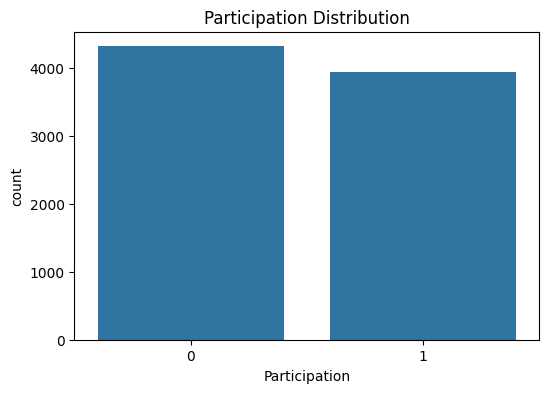

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="Participation",
    data=df
)

plt.title(
    "Participation Distribution"
)

plt.show()

In [ ]:
df.to_excel(
    "Week3_Prepared_Dataset.xlsx",
    index=False
)

print("Prepared Dataset Saved")

Prepared Dataset Saved


In [ ]:
print(df.shape)
print(df.columns.tolist())

(8262, 20)
['Learner_SignUp_DateTime', 'Opportunity_Id', 'Opportunity_Name', 'Opportunity_Category', 'Opportunity_End_Date', 'First_Name', 'Date_of_Birth', 'Gender', 'Country', 'Institution_Name', 'Current_Intended_Major', 'Entry_created_at', 'Status_Description', 'Status_Code', 'Apply_Date', 'Opportunity_Start_Date', 'Age_at_Signup', 'Signup_Month', 'Signup_Month_Name', 'Participation']


Advanced Feature Engineering & Model-Ready Dataset Creation

In [ ]:
#Create a Copy of Dataset
df_model = df.copy()

print("Working dataset created")

Working dataset created


In [ ]:
#Convert Date Columns
date_columns = [
    "Learner_SignUp_DateTime",
    "Opportunity_Start_Date",
    "Opportunity_End_Date",
    "Apply_Date",
    "Date_of_Birth",
    "Entry_created_at"
]

for col in date_columns:
    if col in df_model.columns:
        df_model[col] = pd.to_datetime(
            df_model[col],
            errors="coerce"
        )

print("Date conversion complete")

Date conversion complete


In [ ]:
#Create Age Feature
from datetime import datetime

current_year = datetime.now().year

df_model["Age"] = (
    current_year -
    df_model["Date_of_Birth"].dt.year
)

df_model["Age"].describe()

,Age
count,8262.000000
mean,26.735536
std,4.335929
min,15.000000
25%,25.000000
50%,26.000000
75%,28.000000
max,60.000000


In [ ]:
#Create Signup Year
df_model["Signup_Year"] = (
    df_model["Learner_SignUp_DateTime"]
    .dt.year
)

In [ ]:
#Create Signup Month
df_model["Signup_Month"] = (
    df_model["Learner_SignUp_DateTime"]
    .dt.month
)

In [ ]:
#Create Signup Quarter
df_model["Signup_Quarter"] = (
    df_model["Learner_SignUp_DateTime"]
    .dt.quarter
)

In [ ]:
#Create Signup Day of Week
df_model["Signup_Day"] = (
    df_model["Learner_SignUp_DateTime"]
    .dt.day_name()
)

In [ ]:
#Create Opportunity Duration
df_model["Opportunity_Duration"] = (
    df_model["Opportunity_End_Date"]
    -
    df_model["Opportunity_Start_Date"]
).dt.days

df_model["Opportunity_Duration"].describe()

,Opportunity_Duration
count,3368.000000
mean,372.470903
std,291.062982
min,-7.000000
25%,63.000000
50%,468.000000
75%,604.000000
max,913.000000


In [ ]:
#Create Application Delay
df_model["Application_Delay"] = (
    df_model["Apply_Date"]
    -
    df_model["Learner_SignUp_DateTime"]
).dt.days

In [ ]:
#Create Opportunity Month
df_model["Opportunity_Month"] = (
    df_model["Opportunity_Start_Date"]
    .dt.month
)

In [ ]:
#Create Opportunity Quarter
df_model["Opportunity_Quarter"] = (
    df_model["Opportunity_Start_Date"]
    .dt.quarter
)

In [ ]:
#Encode High-Level Participation Segments
df_model["Participation_Level"] = np.where(
    df_model["Participation"] == 1,
    "High Participation",
    "Low Participation"
)

In [ ]:
#Missing Value Treatment
numerical_cols = df_model.select_dtypes(
    include=["int64","float64"]
).columns

for col in numerical_cols:
    df_model[col].fillna(
        df_model[col].median(),
        inplace=True
    )

In [ ]:
#
print(df.columns.tolist())


['Learner_SignUp_DateTime', 'Opportunity_Id', 'Opportunity_Name', 'Opportunity_Category', 'Opportunity_End_Date', 'First_Name', 'Date_of_Birth', 'Gender', 'Country', 'Institution_Name', 'Current_Intended_Major', 'Entry_created_at', 'Status_Description', 'Status_Code', 'Apply_Date', 'Opportunity_Start_Date', 'Age_at_Signup', 'Signup_Month', 'Signup_Month_Name', 'Participation']


In [ ]:
#
df["Opportunity_Duration"] = (
    df["Opportunity_End_Date"] -
    df["Opportunity_Start_Date"]
).dt.days


In [ ]:
#
# Create Opportunity Duration

df["Opportunity_Duration"] = (
    df["Opportunity_End_Date"] -
    df["Opportunity_Start_Date"]
).dt.days

# Create Application Delay

df["Application_Delay"] = (
    df["Apply_Date"] -
    df["Learner_SignUp_DateTime"]
).dt.days


In [ ]:
#
for col in df.columns:
    print(col)


Learner_SignUp_DateTime
Opportunity_Id
Opportunity_Name
Opportunity_Category
Opportunity_End_Date
First_Name
Date_of_Birth
Gender
Country
Institution_Name
Current_Intended_Major
Entry_created_at
Status_Description
Status_Code
Apply_Date
Opportunity_Start_Date
Age_at_Signup
Signup_Month
Signup_Month_Name
Participation
Opportunity_Duration
Application_Delay


In [ ]:
#
# Fill missing values

df["Opportunity_Duration"] = (
    df["Opportunity_Duration"]
    .fillna(df["Opportunity_Duration"].median())
)

df["Application_Delay"] = (
    df["Application_Delay"]
    .fillna(df["Application_Delay"].median())
)

print("Missing values handled successfully!")

Missing values handled successfully!


In [ ]:
#
# Signup Quarter
df["Signup_Quarter"] = (
    df["Learner_SignUp_DateTime"].dt.quarter
)

# Signup Day
df["Signup_Day"] = (
    df["Learner_SignUp_DateTime"].dt.day_name()
)

# Birth Year
df["Birth_Year"] = (
    df["Date_of_Birth"].dt.year
)

print("Additional features created successfully!")

Additional features created successfully!


In [ ]:
#
print(df[[
    "Opportunity_Duration",
    "Application_Delay",
    "Signup_Quarter",
    "Signup_Day",
    "Birth_Year"
]].head())

   Opportunity_Duration  Application_Delay  Signup_Quarter Signup_Day  \
0                 604.0                0.0               2  Wednesday   
1                 604.0                0.0               2     Monday   
2                 604.0                4.0               2     Sunday   
3                 604.0               41.0               3    Tuesday   
4                 604.0                0.0               1     Friday   

   Birth_Year  
0        2001  
1        2000  
2        2002  
3        1999  
4        2000  


In [ ]:

positive_status = [
    "Team Allocated",
    "Started",
    "Rewards Award"
]

df["Participation"] = np.where(
    df["Status_Description"].isin(positive_status),
    1,
    0
)

print(df["Participation"].value_counts())

Participation
0    4323
1    3939
Name: count, dtype: int64


In [ ]:
print(df.shape)

(8262, 25)


In [ ]:
print(df.shape)

print(df["Participation"].value_counts())

(8262, 25)
Participation
0    4323
1    3939
Name: count, dtype: int64


In [ ]:
numerical_cols = df_model.select_dtypes(
    include=["int64","float64"]
).columns

for col in numerical_cols:
    df_model[col].fillna(
        df_model[col].median(),
        inplace=True
    )

In [ ]:
categorical_cols = df_model.select_dtypes(
    include=["object"]
).columns

for col in categorical_cols:
    df_model[col].fillna(
        df_model[col].mode()[0],
        inplace=True
    )

In [ ]:
df_model.isnull().sum().sort_values(
    ascending=False
).head(20)

,0
Opportunity_Start_Date,4462
Opportunity_End_Date,1215
Apply_Date,239
Learner_SignUp_DateTime,0
Opportunity_Id,0
First_Name,0
Date_of_Birth,0
Gender,0
Country,0
Institution_Name,0


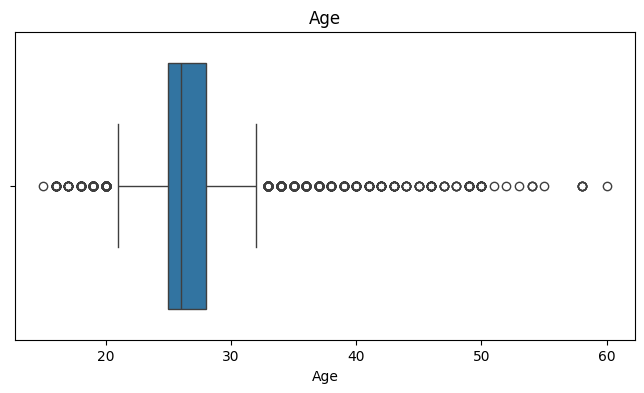

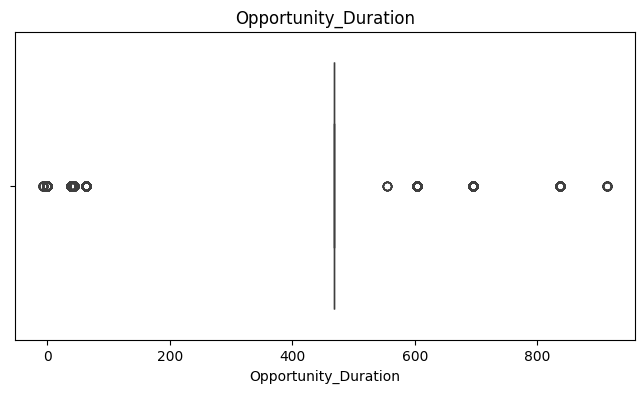

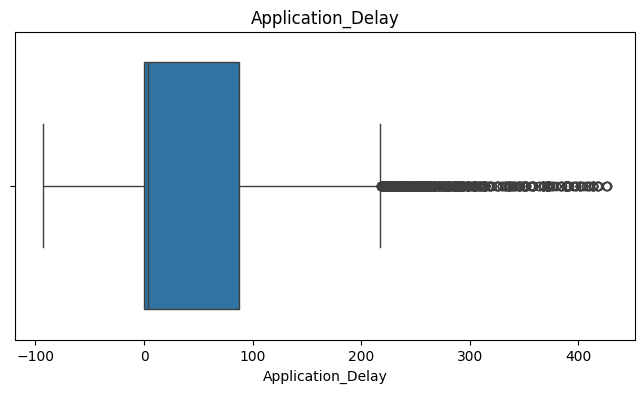

In [ ]:
#Detect Outliers
numeric_features = [
    "Age",
    "Opportunity_Duration",
    "Application_Delay"
]

for col in numeric_features:

    plt.figure(figsize=(8,4))

    sns.boxplot(
        x=df_model[col]
    )

    plt.title(col)

    plt.show()

In [ ]:
#Cap Extreme Outliers
for col in numeric_features:

    q1 = df_model[col].quantile(0.25)
    q3 = df_model[col].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5*iqr
    upper = q3 + 1.5*iqr

    df_model[col] = np.where(
        df_model[col] < lower,
        lower,
        df_model[col]
    )

    df_model[col] = np.where(
        df_model[col] > upper,
        upper,
        df_model[col]
    )

In [ ]:
#2.17 Correlation Analysis
numeric_df = df_model.select_dtypes(
    include=["int64","float64"]
)

corr_matrix = numeric_df.corr()


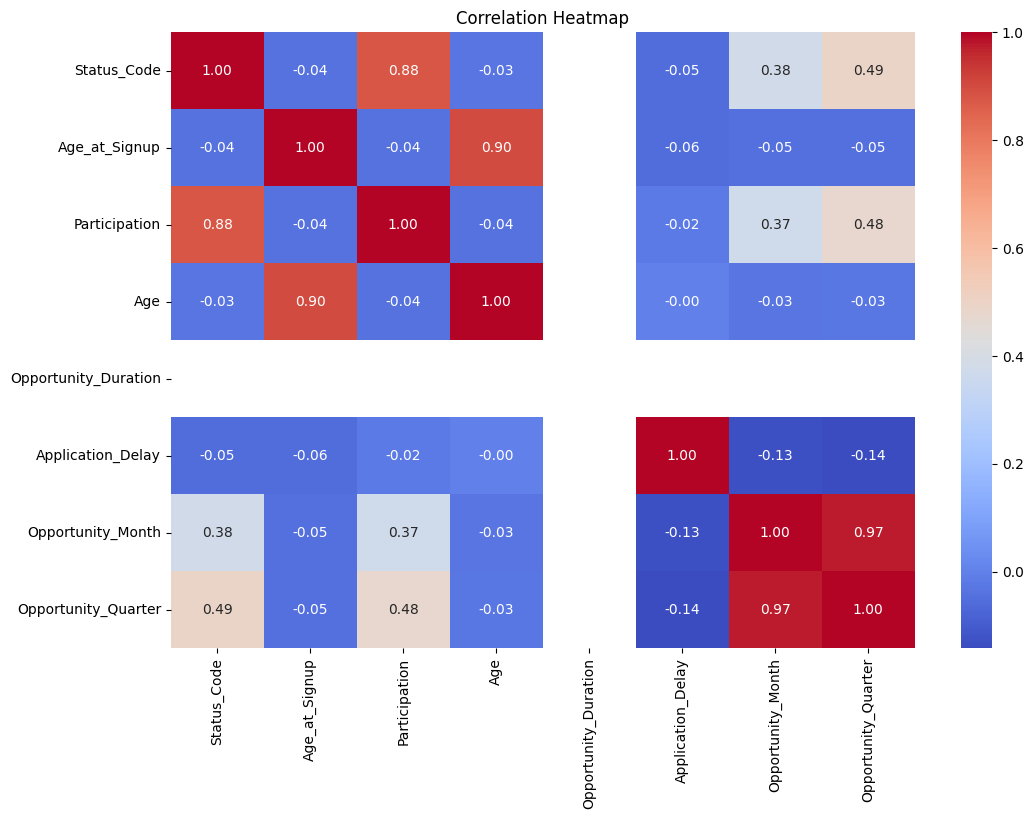

In [ ]:
#
plt.figure(figsize=(12,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
#2.18 Create Final Modeling Dataset
drop_columns = [
    "Status_Description",
    "Participation_Level"
]


In [ ]:
#
existing_drop = [
    col for col in drop_columns
    if col in df_model.columns
]

df_model = df_model.drop(
    columns=existing_drop
)

In [ ]:
#2.19 Save Feature Engineered Dataset
df_model.to_excel(
    "Week3_Feature_Engineered_Dataset.xlsx",
    index=False
)

print(
    "Feature Engineered Dataset Saved Successfully"
)

Feature Engineered Dataset Saved Successfully


In [ ]:
#2.20 Generate Feature Summary Table
feature_summary = pd.DataFrame({
    "Feature_Name": df_model.columns,
    "Data_Type": df_model.dtypes.astype(str)
})

feature_summary


,Feature_Name,Data_Type
Learner_SignUp_DateTime,Learner_SignUp_DateTime,datetime64[ns]
Opportunity_Id,Opportunity_Id,object
Opportunity_Name,Opportunity_Name,object
Opportunity_Category,Opportunity_Category,object
Opportunity_End_Date,Opportunity_End_Date,datetime64[ns]
First_Name,First_Name,object
Date_of_Birth,Date_of_Birth,datetime64[ns]
Gender,Gender,object
Country,Country,object
Institution_Name,Institution_Name,object


In [ ]:
feature_summary.to_excel(
    "Feature_Summary.xlsx",
    index=False
)

Step 3: Build Advanced Machine Learning Models & Compare Performance

In [ ]:
!pip install xgboost -q

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_excel(
    "Week3_Feature_Engineered_Dataset.xlsx"
)

print(df.shape)

(8262, 27)


In [ ]:
target_column = "Participation"

y = df[target_column]

X = df.drop(
    columns=[target_column]
)

In [ ]:
model_features = [

    "Opportunity_Category",
    "Country",
    "Gender",
    "Institution_Name",
    "Current_Intended_Major",

    "Age_at_Signup",
    "Signup_Month",
    "Signup_Quarter",

    "Opportunity_Duration",
    "Application_Delay"
]

target = "Participation"

X = df_model[model_features]
y = df_model[target]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (8262, 10)
y Shape: (8262,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Training Set: (6609, 10)
Testing Set: (1653, 10)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

categorical_features = [
    "Opportunity_Category",
    "Country",
    "Gender",
    "Institution_Name",
    "Current_Intended_Major"
]

numerical_features = [
    "Age_at_Signup",
    "Signup_Month",
    "Signup_Quarter",
    "Opportunity_Duration",
    "Application_Delay"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

categorical_features = [
    "Opportunity_Category",
    "Country",
    "Gender",
    "Institution_Name",
    "Current_Intended_Major"
]

numerical_features = [
    "Age_at_Signup",
    "Signup_Month",
    "Signup_Quarter",
    "Opportunity_Duration",
    "Application_Delay"
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

In [ ]:
models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=1000,
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            random_state=42
        ),

    "XGBoost":
        XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6,
            random_state=42,
            eval_metric="logloss"
        )
}

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    y_pred = pipeline.predict(X_test)

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    results.append({

        "Model": name,

        "Accuracy":
            round(
                accuracy_score(y_test, y_pred),
                4
            ),

        "Precision":
            round(
                precision_score(y_test, y_pred),
                4
            ),

        "Recall":
            round(
                recall_score(y_test, y_pred),
                4
            ),

        "F1":
            round(
                f1_score(y_test, y_pred),
                4
            ),

        "ROC_AUC":
            round(
                roc_auc_score(y_test, y_prob),
                4
            )
    })

print("All Models Trained Successfully")

All Models Trained Successfully


In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC_AUC",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
2,XGBoost,0.8536,0.8991,0.7805,0.8356,0.9166
1,Random Forest,0.8409,0.9070,0.7424,0.8165,0.8765
0,Logistic Regression,0.8397,0.8968,0.7500,0.8169,0.8753


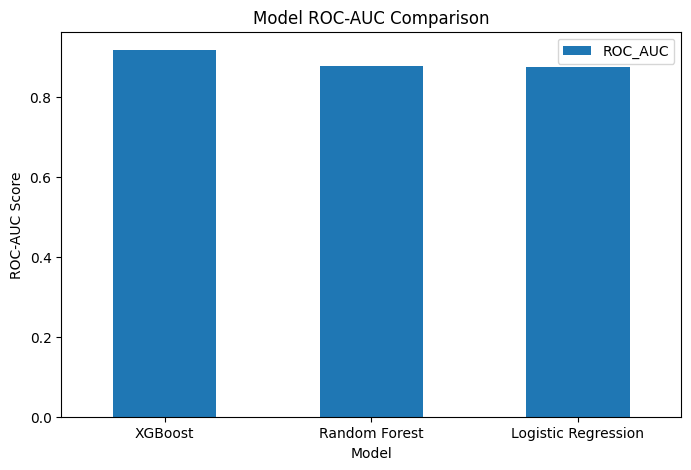

In [ ]:
import matplotlib.pyplot as plt

results_df.plot(
    x="Model",
    y="ROC_AUC",
    kind="bar",
    figsize=(8,5)
)

plt.title("Model ROC-AUC Comparison")
plt.ylabel("ROC-AUC Score")
plt.xticks(rotation=0)

plt.show()

In [ ]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: XGBoost


In [ ]:
import joblib

joblib.dump(
    best_model,
    "Best_Participation_Model.pkl"
)

print("Model Saved Successfully")

Model Saved Successfully


In [ ]:
results_df.to_excel(
    "Model_Comparison_Report.xlsx",
    index=False
)

print("Report Saved")

Report Saved


In [ ]:
# Generate probabilities

y_prob = best_model.predict_proba(X_test)[:,1]

prediction_df = X_test.copy()

prediction_df["Actual"] = y_test.values

prediction_df["Participation_Probability"] = y_prob

prediction_df.head()

,Opportunity_Category,Country,Gender,Institution_Name,Current_Intended_Major,Age_at_Signup,Signup_Month,Signup_Quarter,Opportunity_Duration,Application_Delay,Actual,Participation_Probability
869,Course,United States,Female,Saint Louis University,Computer Science and Information Systems,23,6,2,468.0,34.0,1,0.977054
5493,Event,Nigeria,Female,University Of Ilorin Teaching Hospital,Medicine,23,8,3,468.0,0.0,1,0.991564
5984,Internship,United States,Male,Saint Louis University,Information Systems,23,1,1,468.0,0.0,1,0.204386
6953,Internship,United States,Male,Velgapudi Ramakrishna Siddhartha Engineering ...,Business Analytics,27,7,3,468.0,198.0,0,0.089917
2615,Internship,India,Male,Saint Louis University,Information Systems,21,6,2,468.0,80.0,0,0.283524


In [ ]:
#4.2 Create Priority Rating
def priority_label(prob):

    if prob >= 0.80:
        return "Very High"

    elif prob >= 0.60:
        return "High"

    elif prob >= 0.40:
        return "Medium"

    else:
        return "Low"

prediction_df["Priority"] = (
    prediction_df["Participation_Probability"]
    .apply(priority_label)
)

prediction_df.head()

,Opportunity_Category,Country,Gender,Institution_Name,Current_Intended_Major,Age_at_Signup,Signup_Month,Signup_Quarter,Opportunity_Duration,Application_Delay,Actual,Participation_Probability,Priority
869,Course,United States,Female,Saint Louis University,Computer Science and Information Systems,23,6,2,468.0,34.0,1,0.977054,Very High
5493,Event,Nigeria,Female,University Of Ilorin Teaching Hospital,Medicine,23,8,3,468.0,0.0,1,0.991564,Very High
5984,Internship,United States,Male,Saint Louis University,Information Systems,23,1,1,468.0,0.0,1,0.204386,Low
6953,Internship,United States,Male,Velgapudi Ramakrishna Siddhartha Engineering ...,Business Analytics,27,7,3,468.0,198.0,0,0.089917,Low
2615,Internship,India,Male,Saint Louis University,Information Systems,21,6,2,468.0,80.0,0,0.283524,Low


In [ ]:
#4.3 Top Opportunities by Probability
prediction_df = prediction_df.sort_values(
    by="Participation_Probability",
    ascending=False
)

prediction_df.head(20)

,Opportunity_Category,Country,Gender,Institution_Name,Current_Intended_Major,Age_at_Signup,Signup_Month,Signup_Quarter,Opportunity_Duration,Application_Delay,Actual,Participation_Probability,Priority
5481,Event,Egypt,Male,Helwan University,Business Administration,26,6,2,468.0,0.0,1,0.996188,Very High
5033,Course,India,Female,Dps Ruby Park,Biomedical Engineering,14,7,3,468.0,100.0,1,0.994951,Very High
5448,Event,United States,Male,Saint Louis University,Health Data Science,27,8,3,468.0,0.0,1,0.994424,Very High
5434,Event,United States,Male,Saint Louis University,Other,25,7,3,468.0,78.0,1,0.994175,Very High
8086,Event,Egypt,Female,Mansoura University,Marketing,24,3,1,468.0,1.0,1,0.994141,Very High
5050,Course,Nigeria,Female,South America University,Nursing,18,5,2,468.0,83.0,1,0.992980,Very High
5230,Event,United States,Male,Saint Louis University,Computer Science and Information Systems,22,5,2,468.0,134.0,1,0.992766,Very High
5215,Event,United States,Male,Saint Louis University,Cyber Security,24,6,2,468.0,98.0,1,0.992685,Very High
5601,Event,United States,Female,Saint Louis University,Health Data Science,22,6,2,468.0,13.0,1,0.992653,Very High
74,Course,Nigeria,Male,Uníversity Of Ilorin,Other,23,6,2,468.0,0.0,1,0.992647,Very High


In [ ]:
#4.4 Save Predicted Probabilities
prediction_df.to_excel(
    "Predicted_Probabilities.xlsx",
    index=False
)

print("Predicted Probabilities Saved")


Predicted Probabilities Saved


In [ ]:
#


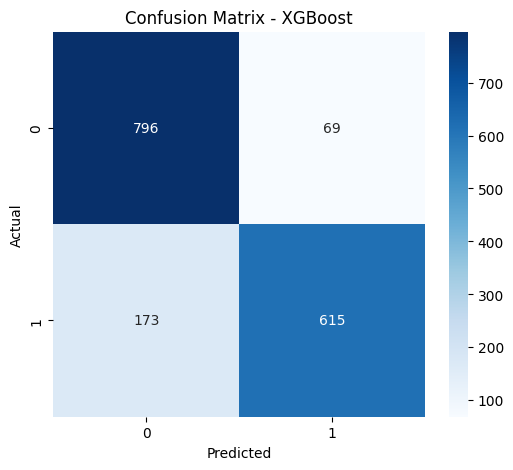

In [ ]:
#5.1 Confusion Matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "Confusion Matrix - XGBoost"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()


In [ ]:
#5.2 Classification Report
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred
    )
)


              precision    recall  f1-score   support

           0       0.82      0.92      0.87       865
           1       0.90      0.78      0.84       788

    accuracy                           0.85      1653
   macro avg       0.86      0.85      0.85      1653
weighted avg       0.86      0.85      0.85      1653



In [ ]:
#6.1 Feature Importance
xgb_model = best_model.named_steps[
    "classifier"
]


In [ ]:
#Get transformed feature names:
feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

In [ ]:
#Create importance dataframe:
importance_df = pd.DataFrame({

    "Feature":
        feature_names,

    "Importance":
        xgb_model.feature_importances_
})

In [ ]:
#6.2 Top 20 Features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(20)


,Feature,Importance
9,cat__Opportunity_Category_Internship,0.581642
1,num__Signup_Month,0.014593
1816,cat__Current_Intended_Major_Health Data Science,0.014338
1844,cat__Current_Intended_Major_Information Systems,0.013182
1848,cat__Current_Intended_Major_Information techno...,0.010905
1535,cat__Institution_Name_Vellore Institute Of Tec...,0.009125
1920,cat__Current_Intended_Major_Other,0.008520
4,num__Application_Delay,0.008426
837,cat__Institution_Name_Lotus Valley Internation...,0.008362
1943,cat__Current_Intended_Major_Public Health,0.008337


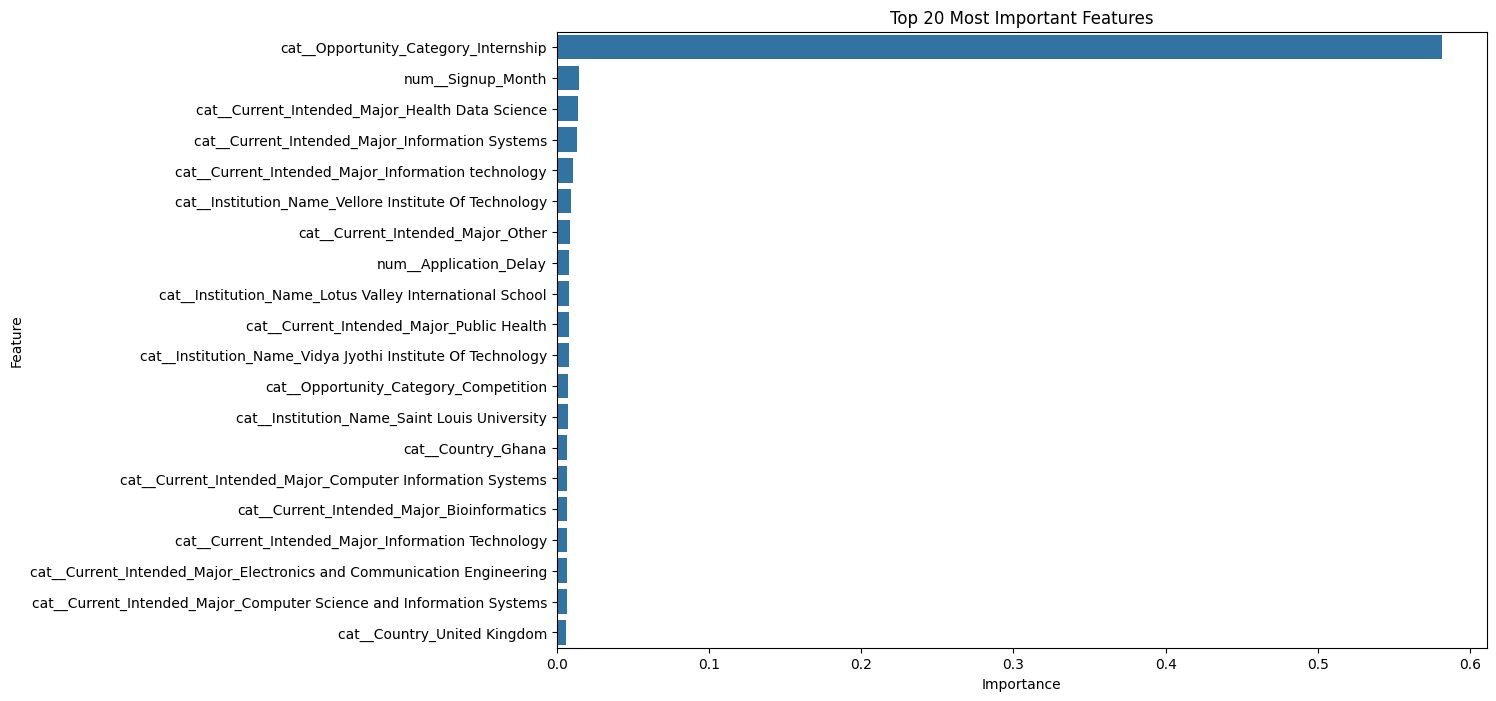

In [ ]:
#6.3 Feature Importance Chart
plt.figure(figsize=(12,8))

top20 = importance_df.head(20)

sns.barplot(
    data=top20,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 20 Most Important Features"
)

plt.show()

In [ ]:
#7.1 Heatmap of Predicted Participation
heatmap_df = prediction_df.pivot_table(

    values="Participation_Probability",

    index="Opportunity_Category",

    columns="Gender",

    aggfunc="mean"
)


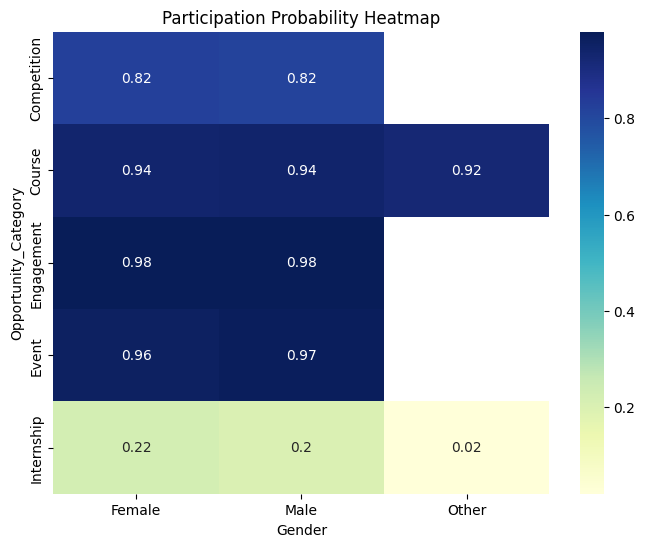

In [ ]:
#7.2 Plot Heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    heatmap_df,
    annot=True,
    cmap="YlGnBu"
)

plt.title(
    "Participation Probability Heatmap"
)

plt.show()

In [ ]:
#8.1 Save Feature Importance
importance_df.to_excel(
    "Feature_Importance.xlsx",
    index=False
)

print("Feature Importance Saved")


Feature Importance Saved


In [ ]:
#8.2 Save Heatmap Data
heatmap_df.to_excel(
    "Participation_Heatmap.xlsx"
)

print("Heatmap Data Saved")

Heatmap Data Saved


In [ ]:
results_df

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
2,XGBoost,0.8536,0.8991,0.7805,0.8356,0.9166
1,Random Forest,0.8409,0.9070,0.7424,0.8165,0.8765
0,Logistic Regression,0.8397,0.8968,0.7500,0.8169,0.8753
